# Telegram 三来源：研究与前向观察审计

## tl;dr

当前没有可验证的交易优势。初始样本中的主群方向观点较稀疏，严格小时规则没有合格信号；CryptoQuant 历史编辑稿不用于还原原始时点，API 群只做技术风险观察。前向账本已独立启动，尚无成熟收益，不能把空样本解释为零收益。

## Context & Methods

决策：是否值得为三个来源继续收集前向证据，暂不注册实盘策略。初始规则在历史价格读取前冻结：BTC、每小时至少5个方向观点账号、多空不平衡绝对值≥0.4、顺势/反向分别观察、持有6小时；CryptoQuant方向观点持有24小时。基于文本密度增加的6小时窗口只用于前向探索，不声称是历史留出验证。

### Key Assumptions

- 用户已确认研究及AI处理授权，具体依据待补充；只输出汇总。
- 主群触及12,000条采集上限，只覆盖约38小时；其余两个来源按45天边界采集。
- 发送账号经本地加盐去标识化，账号数不等同于独立真人或分析师数。
- 模型只接收脱敏文本、不接收价格；Gemini 2.5 Flash另次复核不构成独立人工真值。
- 编辑过的历史、转发、机器人及不明确资产的内容不作为历史交易信号。前向以首次接收和解析完成为可用时点。
- 收益计划扣20bp往返成本、40bp压力成本及实际资金费；缺数据保留未结算状态。

## Data

### 1. Verify the frozen aggregate inputs

源记录、协议和行情回执保存在本机忽略目录。这里使用不含正文或身份信息的元数据副本；通过固定哈希防止后续采集改变这次分析。

In [1]:
from pathlib import Path
import json,hashlib
from collections import Counter,defaultdict
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT=Path(r"F:\9_Crypto\crypto_trading_system")
DATA=ROOT/'data/research/telegram_live_20261024'
OUT=ROOT/'reports/telegram_live_research_20261024'
raw=(DATA/'research_metadata.json').read_bytes()
assert hashlib.sha256(raw).hexdigest()=="fe077bb4d217b68605ecfedf57d84f0b684fe50027a268f4525e8a111f79276e"
rows=json.loads(raw)['rows']
profile=json.loads((DATA/'research_features.json').read_text(encoding='utf-8'))['profile']
pd.DataFrame([{'source':s,'messages':p['messages'],'text_messages':p['text_messages'],'first':p['first'],'last':p['last'],'edited':p['edited'],'directional':p['directional_messages']} for s,p in profile.items()])

source,messages,text_messages,first,last,edited,directional
cryptoquant_official,70,47,2026-09-09T07:47:58+00:00,2026-10-23T13:04:58+00:00,70,0
BinanceChinese,12000,10667,2026-10-22T12:08:49+00:00,2026-10-24T02:24:31+00:00,679,47
Binance_api_Chinese,544,543,2026-09-09T13:38:50+00:00,2026-10-23T17:18:51+00:00,2,0


## Results

### 2. Recompute BTC author coverage

小时级作者数来自实际可见历史快照中的已复核 BTC 观点；不把缺少明确观点解释为中性情绪。

In [2]:
btc=[]
for row in rows:
    if row['channel']!='BinanceChinese' or row['kind']!='directional': continue
    for event in row['events']:
        if event['symbol']=='BTCUSDT' and event['confidence']>=.7:
            btc.append({'at':pd.Timestamp(row['published_at']),'author':row['author_hash'],'side':event['side']})
frame=pd.DataFrame(btc)
frame['hour']=frame['at'].dt.floor('h')
hourly=frame.groupby('hour')['author'].nunique()
assert len(frame)==27 and frame['author'].nunique()==17 and hourly.max()==4
main=[r for r in rows if r['channel']=='BinanceChinese']
first=min(pd.Timestamp(r['published_at']) for r in main).ceil('h')
last=max(pd.Timestamp(r['published_at']) for r in main).floor('h')
index=pd.date_range(first,last-pd.Timedelta(hours=1),freq='h')
visible=hourly.reindex(index,fill_value=0)
diagnostics={'btc_views':len(frame),'btc_authors':int(frame['author'].nunique()),'maximum_hourly_authors':int(hourly.max()),'complete_visible_hours':len(index),'minimum_required_authors':5,'qualified_original_features':0}
(OUT/'diagnostics.json').write_text(json.dumps(diagnostics,indent=2),encoding='utf-8')
diagnostics

{'btc_views': 27, 'btc_authors': 17, 'maximum_hourly_authors': 4, 'complete_visible_hours': 37, 'minimum_required_authors': 5, 'qualified_original_features': 0}

### 3. Coverage against the frozen hourly rule

<notebook>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


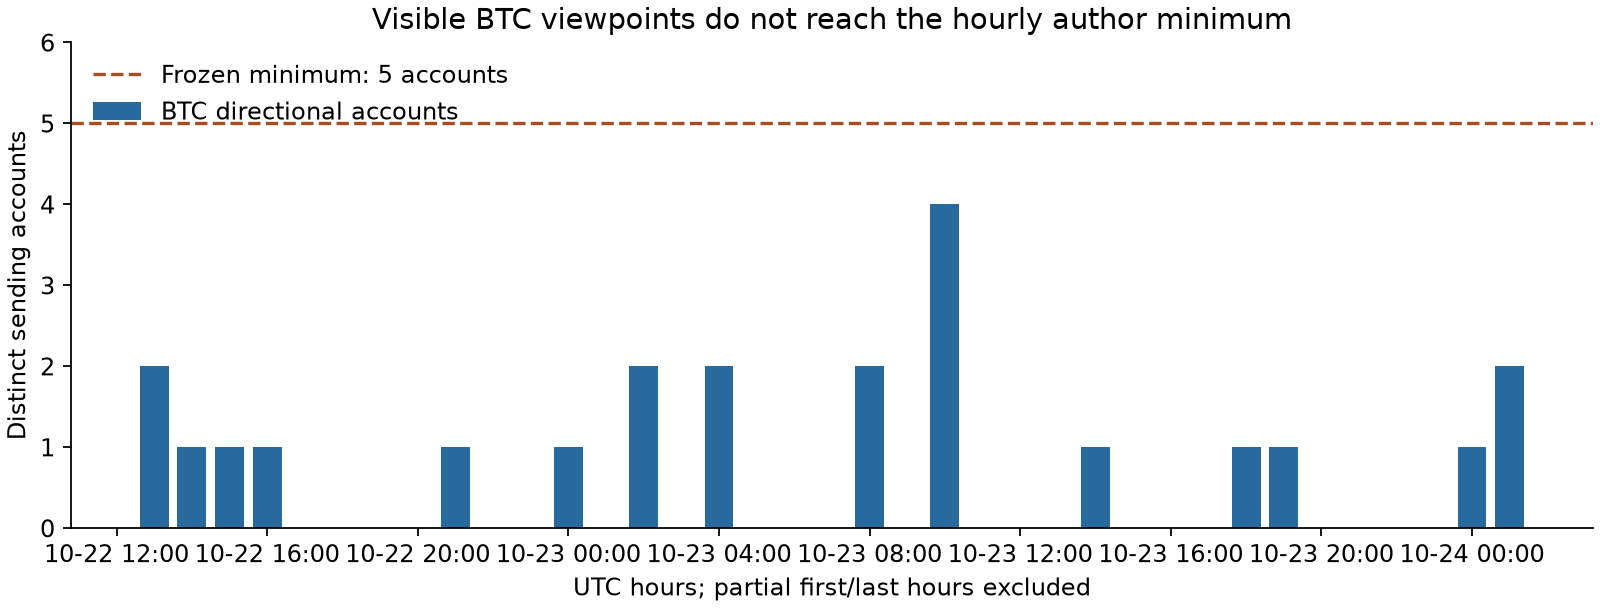

In [3]:
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(10,3.8),layout='constrained')
ax.bar(visible.index,visible.values,width=.032,color='#286a9e',label='BTC directional accounts')
ax.axhline(5,color='#a94d20',linestyle='--',label='Frozen minimum: 5 accounts')
ax.set_ylim(0,6); ax.set_yticks(range(7)); ax.set_ylabel('Distinct sending accounts')
ax.set_title('Visible BTC viewpoints do not reach the hourly author minimum')
ax.set_xlabel('UTC hours; partial first/last hours excluded')
ax.legend(frameon=False,loc='upper left')
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
fig.savefig(OUT/'hourly_btc_authors.png',dpi=160)
plt.show()

### 4. Confirm absence of a return sample

零合格信号不等于收益为零。原规则没有交易样本，因此没有胜率、平均收益或显著性结论。

In [4]:
result=json.loads((DATA/'research_results.json').read_text(encoding='utf-8'))
assert result['feature_count']==0 and result['events']==[]
summary=json.loads((DATA/'forward_summary.json').read_text(encoding='utf-8'))
pd.DataFrame([{'paper_book':key,'decisions_at_snapshot':v['decisions'],'mature_at_snapshot':v['mature_settled'],'mean_net':v['mean_net_per_notional'],'promotion_allowed':v['promotion_allowed']} for key,v in summary['books'].items()])

paper_book,decisions_at_snapshot,mature_at_snapshot,mean_net,promotion_allowed
cq_follow,0,0,None,False
chat_follow,0,0,None,False
chat_contrarian,0,0,None,False
chat_6h_follow,0,0,None,False
chat_6h_contrarian,0,0,None,False


## Takeaways

- 中文主群有可识别的 BTC 观点，但当前窗口不足以验证收益；保持原规则，另行前向观察6小时聚合。
- CryptoQuant 采用首次实际接收版本做未来观察，避免把当前编辑稿回填为当时已知文本。
- API群关注技术故障压力，不将报错词当作看空交易。
- 五个账本分别冻结、分别评估，不混成账户收益；原规则和探索规则不择优删去失败者。
- 观察达到100笔成熟样本及8个日历周后才进行进一步人工研究复核，仍需处理多重比较、独立留出和真实成交假设；任何筛查结果均不自动放行实盘。

交接入口：`docs/TELEGRAM_AGENT_HANDOFF.md`。